0 0.989 0.982
1 0.982 0.985
2 0.995 0.978
3 0.966 0.793
4 0.994 0.342
5 0.996 0.303
6 0.966 0.597
7 0.972 0.459
8 0.959 -0.181
9 0.989 0.068
10 0.995 0.009
11 0.994 -0.008


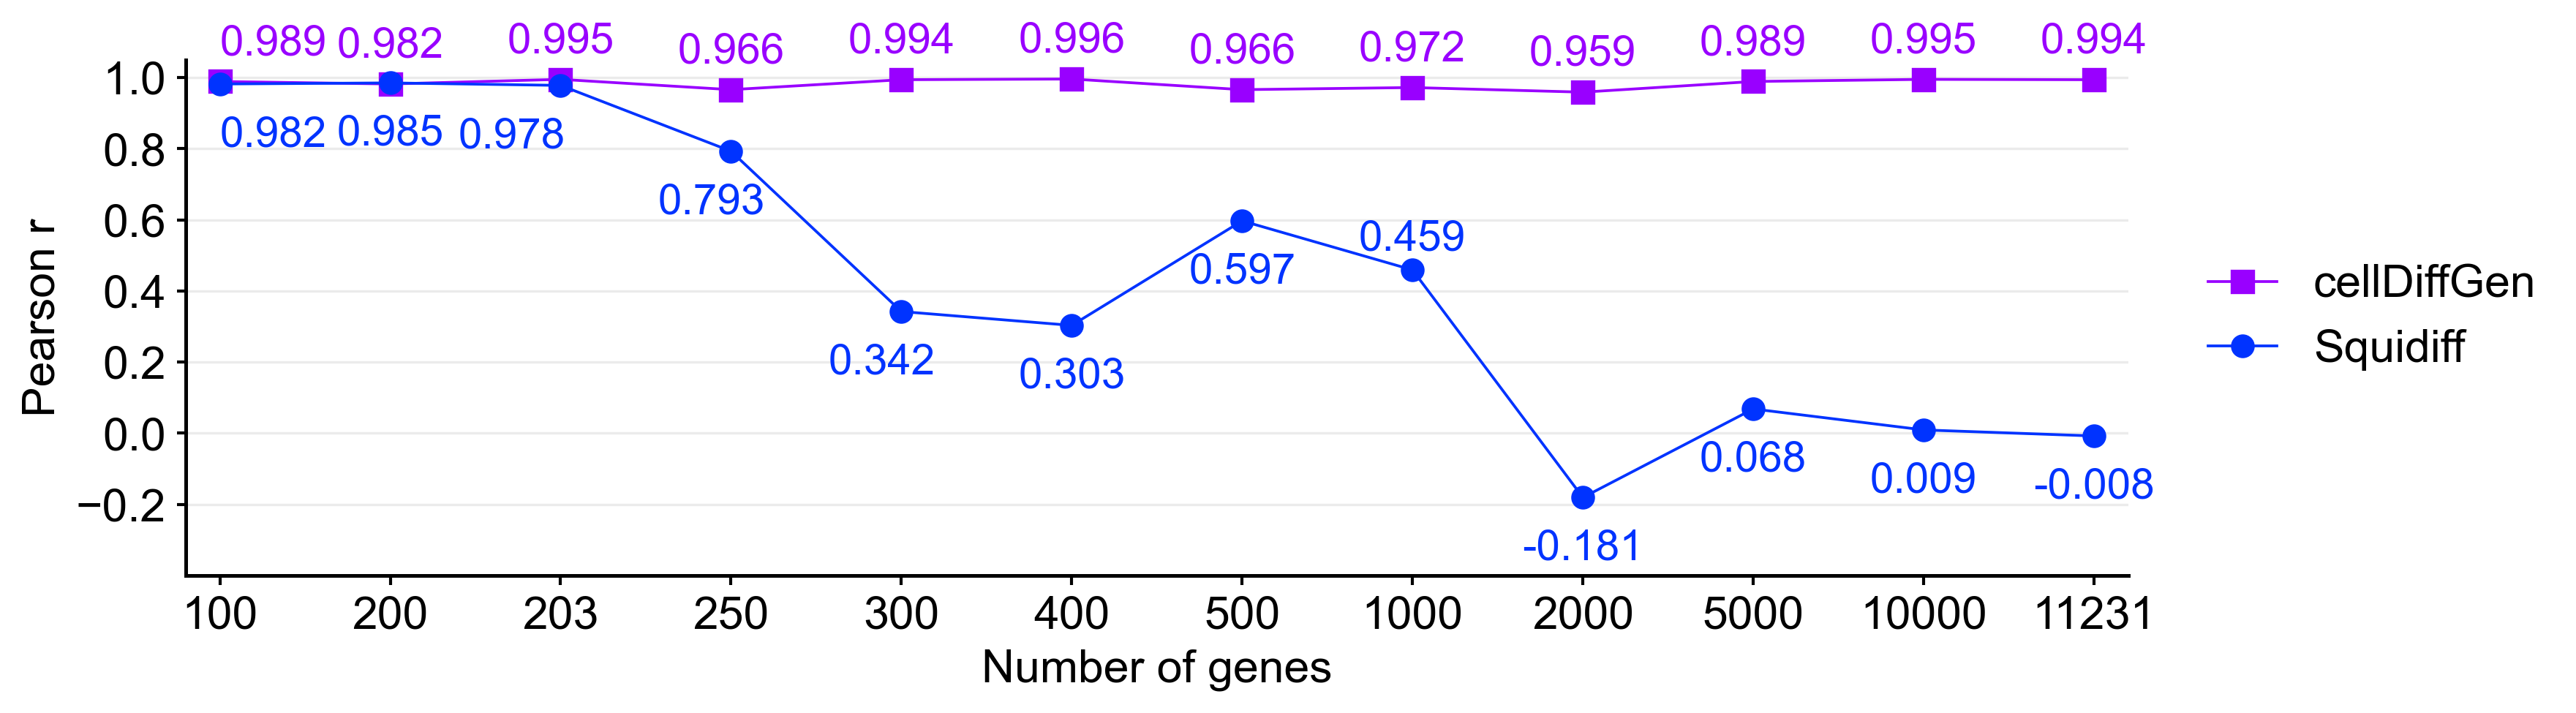

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_manager.fontManager.addfont("../../../../arial.ttf")

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "pdf.fonttype": 42,
    "axes.linewidth": 1.2,
})

x = ["100", "200", "203", "250", "300", "400",
     "500", "1000", "2000", "5000", "10000", "11231"]

y1 = [0.989,0.982,0.995,0.966,0.994,0.996,0.966,0.972,0.959,0.989,0.995,0.994]

y2 = [0.982,0.985,0.978,0.793,0.342,0.303,0.597,0.459,-0.181,0.068,0.009,-0.008]

positions = np.arange(len(x))

# Replace None with your measured SD or SE arrays, if available
y1_error = None
y2_error = None

fig, ax = plt.subplots(figsize=(12, 3.5), dpi=300)
for i, (a, b) in enumerate(zip(y1, y2)):
    print(i,a,b)
    align = "left" if i == 0 else "center"
    # blue_y = ymin - 0.04 if b - ymin < 0.15 else b - 0.04
    ax.text(i, a + 0.05, f"{a:.3f}",ha=align, va="bottom", fontsize=14, color="#9900FF",clip_on=False)
    if i == 2:
        ax.text(i -0.6, b-0.2, f"{b:.3f}",ha="left", va="bottom", fontsize=14, color="#0033FF",clip_on=False)
    elif i == 3 or i == 4:
        ax.text(i+0.2, b-0.2, f"{b:.3f}",ha="right", va="bottom", fontsize=14, color="#0033FF",clip_on=False)
    elif i == 7:
        ax.text(i, b+0.03, f"{b:.3f}",ha=align, va="bottom", fontsize=14, color="#0033FF",clip_on=False)
    else:
        ax.text(i, b-0.2, f"{b:.3f}",ha=align, va="bottom", fontsize=14, color="#0033FF",clip_on=False)
# Two lines
ax.errorbar(
    positions, y1, yerr=y1_error,
    fmt="s-", color="#9900FF",
    # markerfacecolor="white",
    markersize=7, linewidth=0.9,
    markeredgewidth=0.8,
    capsize=2, elinewidth=0.7,
    label="cellDiffGen"
)

ax.errorbar(
    positions, y2, yerr=y2_error,
    fmt="o-", color="#0033ff",
    # markerfacecolor="white",
    markersize=7, linewidth=0.9,
    markeredgewidth=0.8,
    capsize=2, elinewidth=0.7,
    label="Squidiff"
)

ax.set_xticks(positions)
# ax.set_xticklabels(x, rotation=45, ha="right")
ax.set_xticklabels(x, ha="center")
ax.set_xlim(-0.2, len(x) - 0.8)

# Extra room above 1 keeps the markers fully visible
ax.set_ylim(-0.4, 1.05)
ax.set_yticks([-0.2,0,0.2,0.4,0.6,0.8,1])

ax.set_xlabel("Number of genes")
ax.set_ylabel("Pearson r")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", length=3, width=1)
# ax.grid(False)
ax.grid(axis="y", alpha=0.25)
# ax.grid(axis="x", alpha=0.25)
ax.legend(
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    handlelength=1.5
)

fig.tight_layout()
fig.savefig("line_plot.pdf", bbox_inches="tight")
plt.show()